# Make grids for example data

## Code setup

In [1]:
import os
from dataclasses import dataclass
import warnings

import numpy as np
import geopandas as gpd
import pandas as pd
import json  # to load dict
import matplotlib.pyplot as plt
import geojson  # to load and save outlines
import shapely.plotting  # to plot outlines

# Add path to package:
import sys
sys.path.insert(0,'../')
import isopods.grid
import isopods.stick
import isopods.outline
import isopods.convert

In [2]:
@dataclass(frozen=True)
class Paths:
    '''Singleton object for storing paths to data and database.'''

    dir_data: str = '.'
    
    lsoa_filename: str = 'lsoa2011_devon.geojson'
    district_filename: str = 'lsoa2011_devon_districts.geojson'
    lookup_filename: str = 'lookup_lsoa2011_district_devon.csv'
    
    grid_df_savename: str = 'lsoa2011_devon_1k_grid_df.csv'
    dict_savename: str = 'lsoa2011_devon_1k_grid_dict.json'
    lsoa_grid_data_savename: str = 'lsoa2011_devon_1k_grid_data.csv'
    lsoa_grid_mask_savename: str = 'lsoa2011_devon_1k_grid_mask.csv'
    district_grid_data_savename: str = 'district2011_devon_1k_grid_data.csv'
    district_grid_mask_savename: str = 'district2011_devon_1k_grid_mask.csv'
    outline_savename: str = 'districts2011_devon_1k_outlines.geojson'
    midpoints_savename: str = 'districts2011_devon_1k_midpoints.csv'

paths = Paths()

## Create grid data

In [3]:
def make_grids(gdf, cell_width=5000, cell_height=5000):
    """cell width and height are in metres for British National Grid"""
    bbox_shapes = gdf.total_bounds    
    bbox_grid = isopods.grid.make_grid_bounds_containing_bbox(
        bbox_shapes, cell_width, cell_height)
    transform_dict = isopods.grid.make_transform_dict(
        bbox_grid, cell_width, cell_height)
    
    # Check that grid setup is sensible:
    print(bbox_shapes)  # xmin, ymin, xmax, ymax
    display(transform_dict)
    
    # Stick shapes to grid:    
    df_props = isopods.stick.stick_shapes_to_grid(
        gdf, **transform_dict, print_progress=True)
    
    # Check the cells with overlapping polygons.
    # Should see that prop_cell_covered is always less than 1.001.
    m = df_props['prop_cell_covered'] >= 1.001
    if len(df_props[m]) > 0:
        warnings.warn('Check the overlapping polygons.', UserWarning)
    else:
        pass

    return df_props, transform_dict 

In [4]:
# Load in shape data.
# Make sure the GeoDataFrame index is the label for each region.
p = os.path.join(paths.dir_data, paths.lsoa_filename)
gdf = gpd.read_file(p).set_index('LSOA11CD')
gdf['geometry'] = gdf.make_valid()
# Check the coordinate reference system (CRS):
print(f'{gdf.crs.name} EPSG:{gdf.crs.to_epsg()}')

# Make the data for the grids.
df_props, transform_dict = make_grids(
    gdf, cell_width=1000, cell_height=1000)
# Save to file:
p = os.path.join(paths.dir_data, paths.grid_df_savename)
df_props.to_csv(p)
p = os.path.join(paths.dir_data, paths.dict_savename)
with open(p, 'w') as f: 
    json.dump(transform_dict, f)

# Convert to arrays of LSOA and district labels.
arr_lsoa = isopods.convert.convert_df_to_2darray(
    df_props, 'label_majority', **transform_dict)
# Load in LSOA to district name lookup:
p = os.path.join(paths.dir_data, paths.lookup_filename)
dict_lookup = pd.read_csv(p, index_col='LSOA11CD').squeeze().to_dict()
arr_districts = isopods.convert.convert_grid_values(
    arr_lsoa, dict_lookup)
# Outlines:
dict_polys = isopods.outline.convert_grid_to_polys(arr_districts)
dict_polys = isopods.outline.transform_poly_dict_coords(dict_polys,
                                                              transform_dict)
# Midpoints
try:
    labels_unique = np.unique(arr_districts.compressed())  # masked array
except AttributeError:
    labels_unique = np.unique(arr_districts)  # normal array
coords_pix = isopods.convert.pick_midpoints_for_regions(
    arr_districts, labels_unique)
coords = isopods.grid.transform_coords_to_grid(
    coords_pix, **transform_dict)
df_meds = pd.DataFrame(
    coords,
    index=pd.Series(labels_unique, name='region'),
    columns=['x_mid', 'y_mid']
)

# Save grid data and masks separately:
np.savetxt(paths.lsoa_grid_data_savename, arr_lsoa.data,
           delimiter=',', fmt='%s')
np.savetxt(paths.lsoa_grid_mask_savename, arr_lsoa.mask.astype(int),
           delimiter=',', fmt='%i')

np.savetxt(paths.district_grid_data_savename, arr_districts.data,
           delimiter=',', fmt='%s')
np.savetxt(paths.district_grid_mask_savename, arr_districts.mask.astype(int),
           delimiter=',', fmt='%i')

# Save outlines:
fc = isopods.outline.convert_dict_polys_to_featurecollection(dict_polys)
p = os.path.join(paths.dir_data, paths.outline_savename)
with open(p, 'w') as f:
    geojson.dump(fc, f)

# Save midpoints:
p = os.path.join(paths.dir_data, paths.midpoints_savename)
df_meds.to_csv(p)

OSGB36 / British National Grid EPSG:27700
[212711.6182  34957.4029 337605.812  151204.9973]


{'xmin': np.float64(212000.0),
 'ymax': np.float64(152000.0),
 'cell_width': 1000,
 'cell_height': 1000,
 'n_cols': 126,
 'n_rows': 118,
 'xmax': np.float64(338000.0),
 'ymin': np.float64(34000.0)}

100.0% of cells checked

/home/anna/geography/isopods/data/../isopods/stick.py:107: UserWarning: Overlapping polygons present in 80 cells: overlap area will be counted twice.
  warnings.warn((


## Re-load the data

Load in the data from file:

In [5]:
# Load in shape data.
# Make sure the GeoDataFrame index is the label for each region.
p = os.path.join(paths.dir_data, paths.lsoa_filename)
gdf = gpd.read_file(p).set_index('LSOA11CD')
gdf['geometry'] = gdf.make_valid()
# Check the coordinate reference system (CRS):
print(f'{gdf.crs.name} EPSG:{gdf.crs.to_epsg()}')

OSGB36 / British National Grid EPSG:27700


In [6]:
p = os.path.join(paths.dir_data, paths.district_filename)
gdf_districts = gpd.read_file(p).set_index('area_name')
gdf_districts['geometry'] = gdf_districts.make_valid()
# Check the coordinate reference system (CRS):
print(f'{gdf_districts.crs.name} EPSG:{gdf_districts.crs.to_epsg()}')

OSGB36 / British National Grid EPSG:27700


In [7]:
p = os.path.join(paths.dir_data, paths.grid_df_savename)
# Use converters to turn proportion data from strings to lists.
converters = {
    'label_props': lambda x: (
        x.replace("'", '').replace(',', '')[1:-1].split()),
    'area_props': lambda x: [float(f) for f in x[1:-1].split()]
}
df_props = pd.read_csv(p, index_col=0, converters=converters)

In [8]:
p = os.path.join(paths.dir_data, paths.dict_savename)
with open(p, 'r') as f:
    transform_dict = json.load(f)

In [9]:
p = os.path.join(paths.dir_data, paths.lsoa_grid_data_savename)
lsoa_grid_data = np.loadtxt(p, dtype=str, delimiter=',')
p = os.path.join(paths.dir_data, paths.lsoa_grid_mask_savename)
lsoa_grid_mask = np.loadtxt(p, dtype=bool, delimiter=',')

arr_lsoa = np.ma.MaskedArray(
    lsoa_grid_data, mask=lsoa_grid_mask, dtype=object)

In [10]:
p = os.path.join(paths.dir_data, paths.district_grid_data_savename)
district_grid_data = np.loadtxt(p, dtype=str, delimiter=',')
p = os.path.join(paths.dir_data, paths.district_grid_mask_savename)
district_grid_mask = np.loadtxt(p, dtype=bool, delimiter=',')

arr_districts = np.ma.MaskedArray(
    district_grid_data, mask=district_grid_mask, dtype=object)

In [11]:
p = os.path.join(paths.dir_data, paths.outline_savename)
with open(p, 'r') as f:
    gj = geojson.load(f)

dict_polys = isopods.outline.convert_featurecollection_to_dict_polys(gj)

In [12]:
p = os.path.join(paths.dir_data, paths.midpoints_savename)
df_meds = pd.read_csv(p, index_col='region')

In [13]:
p = os.path.join(paths.dir_data, paths.grid_df_savename)
# Use converters to turn proportion data from strings to lists.
converters = {'label_props': lambda x: x.replace("'", '')[1:-1].split(),
              'area_props': lambda x: [float(f) for f in x[1:-1].split()]}
d = pd.read_csv(p, index_col=0)#, converters=converters)

In [14]:
d['label_props'].iloc[0]

"['E01020288']"

In [15]:
df_props

,cell_row,cell_col,label_props,area_props,prop_cell_covered,label_majority,overlapping_polys
cell_label,,,,,,,
109,109,0,[E01020288],[1.0],0.000,E01020288,0
110,110,0,[E01020288],[1.0],0.124,E01020288,0
111,111,0,[E01020288],[1.0],0.089,E01020288,0
112,112,0,[E01020288],[1.0],0.000,E01020288,0
113,113,0,[E01020288],[1.0],0.047,E01020288,0
...,...,...,...,...,...,...,...
14697,65,124,[E01019886],[1.0],0.996,E01019886,0
14698,66,124,[E01019886],[1.0],0.973,E01019886,0
14699,67,124,[E01019886],[1.0],0.002,E01019886,0


## Plot the results

Quick check of the results.

Function to assign random values to shapes for the sake of plotting:

In [16]:
def convert_labels_to_values(arr):
    # Generate random values for regions:
    labels_unique = np.unique(arr.compressed())  # only valid cells
    np.random.shuffle(labels_unique)
    d = dict(zip(labels_unique, range(len(labels_unique))))

    arr_values = isopods.convert.convert_grid_values(arr, d)
    return arr_values

In [17]:
np.random.seed(42)
arr_lsoa_values = convert_labels_to_values(arr_lsoa)
arr_districts_values = convert_labels_to_values(arr_districts)

Plot the grid:

In [18]:
# For plotting the grid with imshow:
extent = (transform_dict['xmin'], transform_dict['xmax'],
          transform_dict['ymin'], transform_dict['ymax'])

Does LSOA grid line up with original shapes?

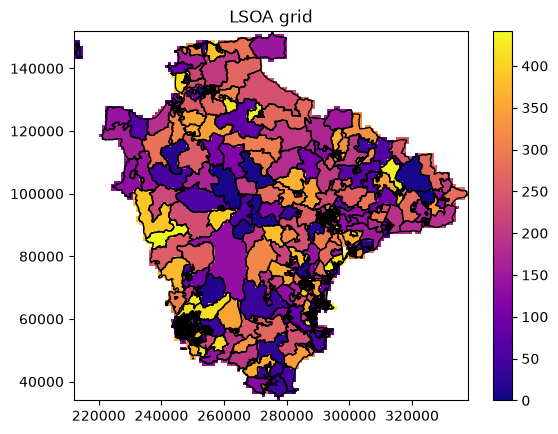

In [19]:
fig, ax = plt.subplots()
cmap = plt.get_cmap('plasma')
cl = ax.imshow(arr_lsoa_values, origin='lower', extent=extent, cmap=cmap)
plt.colorbar(cl)
# Overlay shapes:
gdf.plot(ax=ax, facecolor='None', edgecolor='k')
ax.set_title('LSOA grid')
plt.show()

Does district grid line up with original shapes?

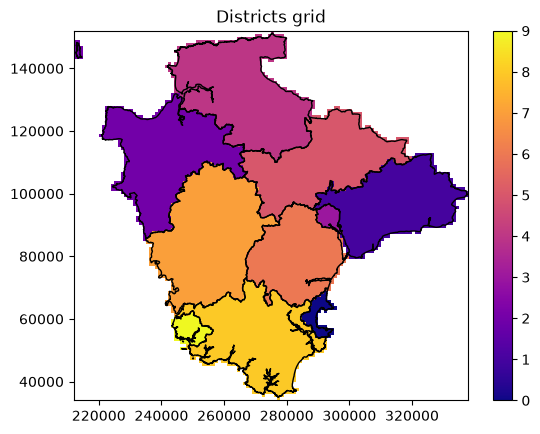

In [20]:
fig, ax = plt.subplots()
cmap = plt.get_cmap('plasma')
cl = ax.imshow(arr_districts_values, origin='lower', extent=extent, cmap=cmap)
plt.colorbar(cl)
# Overlay shapes:
gdf_districts.plot(ax=ax, facecolor='None', edgecolor='k')
ax.set_title('Districts grid')
plt.show()

Do outlines line up with grid?

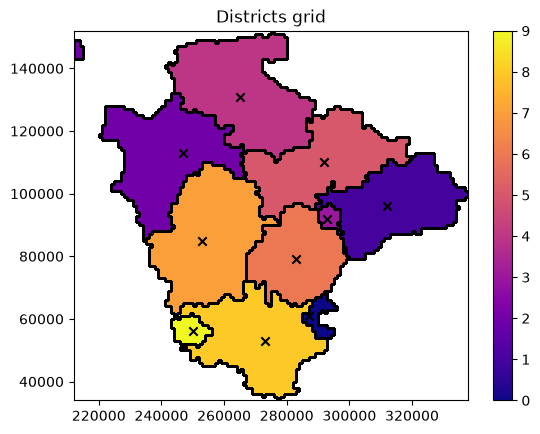

In [21]:
fig, ax = plt.subplots()
cmap = plt.get_cmap('plasma')
cl = ax.imshow(arr_districts_values, origin='lower', extent=extent,
               cmap=cmap, interpolation='None')
plt.colorbar(cl)
# Overlay outlines:
for region, poly in dict_polys.items():
    # Convert polygon to a matplotlib patch:
    # Need antialiased=False to make borders appear to line up with
    # grid. Underlying shapes fine, but antialiased=True makes them
    # look offset in places.
    p = shapely.plotting.patch_from_polygon(
        poly, facecolor=(0, 0, 0, 0), edgecolor='k', antialiased=False)
    ax.add_patch(p)

# Midpoints:
ax.scatter(df_meds['x_mid'], df_meds['y_mid'], marker='x', color='k')

ax.set_title('Districts grid')

plt.show()